# 5. Moving notes without making them sound artificial

We know each note's target. Now we have to **change the pitch of a recorded voice** by a few cents or a few
semitones, without changing its timing, its vowel or its character. This is where most "auto-tuned" sounds
come from, and where this project hit two real bugs. This notebook explains:

1. why simply playing faster doesn't work,
2. the phase vocoder (the idea behind Rubber Band, the library used),
3. **formants**: why a shifted voice can sound like a different person,
4. how the app renders each note separately and crossfades it in,
5. bug 1: per-sample pitch curves → chirps,
6. bug 2: cutting notes into pieces → "singing in front of a fan".

In [1]:
%matplotlib inline
import warnings; warnings.filterwarnings("ignore")  # hide library chatter (progress bars etc.)
import numpy as np
import matplotlib.pyplot as plt
import librosa
from nbtools import *   # synthetic sounds, play(), plots (see nbtools.py)
plt.rcParams["figure.dpi"] = 90

## 5.1 The naive way: play it faster

Playing a recording faster raises its pitch (more cycles per second), but it also makes it **shorter**: a
tape at double speed is an octave higher and lasts half as long. Resampling is the digital version. We need
the opposite combination: **same duration, different pitch**.

In [2]:
note = voice_like([57, 59, 61], note_s=0.6, vibrato_cents=20)
factor = 2 ** (3 / 12)                                   # +3 semitones
faster = librosa.resample(note[0], orig_sr=SR, target_sr=int(SR / factor))   # fewer samples, played at SR
print(f"original {note.shape[1] / SR:.2f} s, 'faster' version {len(faster) / SR:.2f} s")
play(note, label="original")
play(faster, label="+3 semitones by playing faster: shorter, and the voice sounds smaller (chipmunk)")

original 2.04 s, 'faster' version 1.72 s
original


+3 semitones by playing faster: shorter, and the voice sounds smaller (chipmunk)


## 5.2 The phase vocoder

The trick: **stretch time without changing pitch**, then resample. To stretch time, work in the
spectrogram (notebook 1):

1. cut the sound into overlapping frames and take each frame's spectrum (STFT),
2. lay the frames back down **further apart** (or interpolate extra frames), which stretches time,
3. fix up each frequency's **phase** so consecutive frames still join smoothly (the "vocoder" part:
   each bin's phase advance tells you its exact frequency),
4. overlap-add the frames back into a waveform (inverse STFT).

Stretch by 2^(3/12), then resample back to the original length, and you get +3 semitones at the same duration.
Real implementations add a lot of care: transient detection (keeping drum hits and consonants sharp),
phase locking between harmonics, adaptive window sizes. The app uses **Rubber Band** (R3 engine) through
Spotify's `pedalboard` library: `pitch.shift_pitch(audio, semitones)`.

In [3]:
from songpolish.pitch import shift_pitch
shifted = shift_pitch(note, 3.0)
print(f"length kept: {note.shape[1]} -> {shifted.shape[1]} samples")
play(shifted, label="+3 semitones with Rubber Band: same duration")

length kept: 89964 -> 89964 samples
+3 semitones with Rubber Band: same duration


## 5.3 Formants: the shape that makes a vowel

A voice has two independent parts:

* the **source**: the vocal folds vibrating at $f_0$, producing a stack of harmonics (notebook 1);
* the **filter**: the throat and mouth, whose shape boosts some frequency regions. These resonances are
  the **formants**. Their positions decide which **vowel** you hear ("ah" has formants near 700 and 1200 Hz,
  "ee" near 300 and 2300 Hz) and much of who is singing.

The spectrum of a sung vowel is harmonics *under an envelope*. When you shift pitch, the harmonics should
move but the **envelope should stay put**, because the singer's mouth did not change shape. A naive shift
moves both: shifted up, everybody sounds like a child; down, like a giant. **Formant preservation** estimates
the envelope (e.g. with a smoothed spectrum or cepstrum), shifts the harmonics, and re-applies the original
envelope.

Let's make an "ah" by filtering our harmonic voice with two resonances, then shift it up 5 semitones
with and without formant preservation.

'ah' at E3


+5 st, formants moved with it (the 'mouth' got smaller)


+5 st, formants preserved (same vowel, higher note)


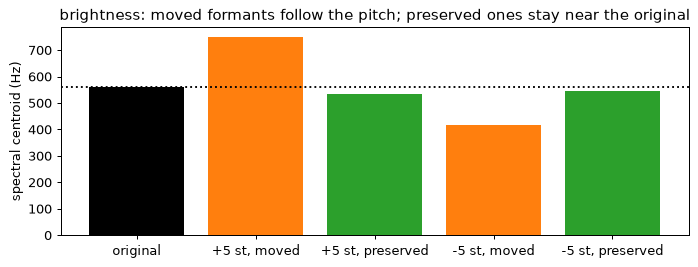

original            561 Hz (+0%)
+5 st, moved        749 Hz (+33%)
+5 st, preserved    533 Hz (-5%)
-5 st, moved        417 Hz (-26%)
-5 st, preserved    546 Hz (-3%)


In [4]:
import pedalboard
from scipy.signal import lfilter
def resonance(y, freq, bw):                  # a 2-pole resonator: a simple formant
    r = np.exp(-np.pi * bw / SR); th = 2 * np.pi * freq / SR
    return lfilter([1 - r], [1, -2 * r * np.cos(th), r * r], y)
src = voice_like([52], note_s=1.5, vibrato_cents=15)[0]
ah = (resonance(src, 700, 130) + 0.6 * resonance(src, 1200, 150)).astype(np.float32)
ah = 0.3 * ah / np.abs(ah).max()
up = lambda keep: pedalboard.time_stretch(ah[None], SR, stretch_factor=1.0, pitch_shift_in_semitones=5.0,
                                          high_quality=True, preserve_formants=keep)[0, :len(ah)]
plain, kept = up(False), up(True)
play(ah, label="'ah' at E3")
play(plain, label="+5 st, formants moved with it (the 'mouth' got smaller)")
play(kept, label="+5 st, formants preserved (same vowel, higher note)")

# The spectral centroid is the "centre of mass" of the spectrum: a simple, robust number for how
# bright a sound is. Formants decide most of it, so it should stay put when formants are preserved.
centroid = lambda y: float(np.median(librosa.feature.spectral_centroid(y=y, sr=SR)))
down = lambda keep: pedalboard.time_stretch(ah[None], SR, stretch_factor=1.0, pitch_shift_in_semitones=-5.0,
                                            high_quality=True, preserve_formants=keep)[0, :len(ah)]
rows = [("original", centroid(ah)),
        ("+5 st, moved", centroid(plain)), ("+5 st, preserved", centroid(kept)),
        ("-5 st, moved", centroid(down(False))), ("-5 st, preserved", centroid(down(True)))]
fig, ax = plt.subplots(figsize=(9, 3))
ax.bar([r[0] for r in rows], [r[1] for r in rows], color=["k", "C1", "C2", "C1", "C2"])
ax.axhline(rows[0][1], color="k", ls=":"); ax.set_ylabel("spectral centroid (Hz)")
ax.set_title("brightness: moved formants follow the pitch; preserved ones stay near the original")
plt.show()
for name, c in rows: print(f"{name:17s} {c:5.0f} Hz ({100 * (c / rows[0][1] - 1):+.0f}%)")

The app always preserves formants. For the small moves it usually makes (a few tens of cents), the
difference is tiny either way.

## 5.4 One note at a time, with crossfades

Each note has its **own** shift (−27 cents for one, +1 semitone for the next, 0 for the one in tune). The app
(`pitch.apply_corrections`):

1. renders **each note separately** with one constant Rubber Band shift, plus 100 ms of context on each
   side so the algorithm has settled when the note starts,
2. blends the rendered note into the original with **20 ms crossfades**: $\sin^2$ ramps. Because
   $\sin^2 + \cos^2 = 1$, the fade-out of one signal and the fade-in of the other always sum to exactly 1,
   so there is no dip or bump in level,
3. everything between corrected notes (breaths, consonants, silence) is the **untouched original**.

Durations never change, so the voice stays in time with the guitar.

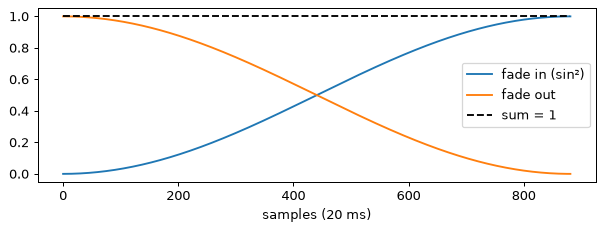

2/3 notes nudged; average error 25 cents, average shift 35 cents.
measured before: ['60.34', '62.03', '63.64']


measured after:  ['60.00', '62.03', '64.00']
before


after


In [5]:
from songpolish.pitch import NoteShift, apply_corrections, CROSSFADE_S
fade = int(CROSSFADE_S * SR)
ramp = np.sin(np.linspace(0, np.pi / 2, fade)) ** 2
fig, ax = plt.subplots(figsize=(8, 2.5))
ax.plot(ramp, label="fade in (sin²)"); ax.plot(ramp[::-1], label="fade out"); ax.plot(ramp + ramp[::-1], "k--", label="sum = 1")
ax.set_xlabel("samples (20 ms)"); ax.legend(); plt.show()

melody = voice_like([60.3, 62.0, 63.6], note_s=0.6)          # C +30c, D, D# +60c (i.e. E -40c)
from songpolish.pitch import plan_corrections, detect_notes
shifts, report = plan_corrections(melody, strength=1.0)
fixed = apply_corrections(melody, shifts)
print(report.summary())
print("measured before:", [f"{n.pitch:.2f}" for n in detect_notes(melody)])
print("measured after: ", [f"{n.pitch:.2f}" for n in detect_notes(fixed)])
play(melody, label="before"); play(fixed, label="after")

## 5.5 Bug 1: a pitch *curve* instead of constant shifts

Rubber Band (through pedalboard) can also take a **per-sample array** of pitch shifts: in principle the
most flexible tool, e.g. a smooth curve that bends each note to its target. The first version of the app
did exactly that. Users heard a "repeating noise": every time the value changes, the library emits a
short **burst of artefacts** about 18 dB below the signal (a chirp), and it applies the change about 87 ms
early.

We can show it: a steady 220 Hz tone with seven small shifts. The high-frequency energy (above 2 kHz,
where a pure 220 Hz tone has nothing) reveals the bursts. This is what
`test_note_corrections_add_no_artifacts` guards against.

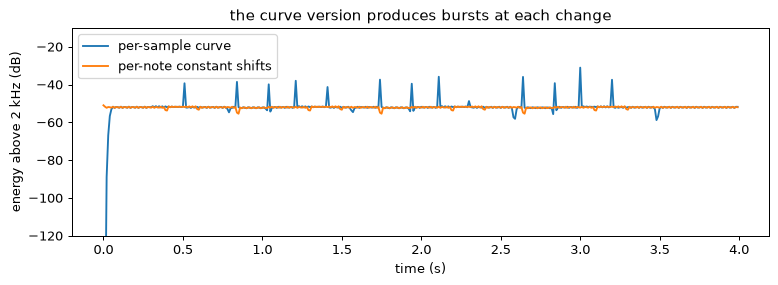

per-sample curve: listen for the clicks/chirps


per-note shifts


In [6]:
from pedalboard import HighpassFilter
t = np.arange(4 * SR) / SR
tone = (0.3 * np.sin(2 * np.pi * 220 * t)).astype(np.float32)[None]
shifts = [NoteShift(int((0.4 + k * 0.45) * SR), int((0.6 + k * 0.45) * SR), 0.3 * (-1) ** k) for k in range(7)]
curve = np.zeros(tone.shape[1])
for s in shifts: curve[s.start:s.end] = s.semitones
as_curve = pedalboard.time_stretch(tone, SR, stretch_factor=1.0, pitch_shift_in_semitones=curve, high_quality=True)[:, :tone.shape[1]]
per_note = apply_corrections(tone, shifts)
def hf_db(y):
    h = HighpassFilter(2000)(HighpassFilter(2000)(np.ascontiguousarray(y, dtype=np.float32), SR), SR)[0]
    h = h[: len(h) // 441 * 441].reshape(-1, 441)
    return 20 * np.log10(np.sqrt((h ** 2).mean(1)) + 1e-9)
fig, ax = plt.subplots(figsize=(10, 3))
tt = np.arange(len(hf_db(per_note))) / 100
ax.plot(tt, hf_db(as_curve)[:len(tt)], label="per-sample curve"); ax.plot(tt, hf_db(per_note), label="per-note constant shifts")
ax.set_ylim(-120, -10); ax.set_xlabel("time (s)"); ax.set_ylabel("energy above 2 kHz (dB)"); ax.legend()
ax.set_title("the curve version produces bursts at each change")
plt.show()
play(as_curve, label="per-sample curve: listen for the clicks/chirps"); play(per_note, label="per-note shifts")

## 5.6 Bug 2: pieces inside a note → "singing in front of a fan"

Long held notes often **sag** (go flat) or **creep** as the singer runs out of breath. An earlier version
corrected that too: it cut every note longer than 0.25 s into **100 ms pieces**, gave each piece its own small
extra shift, and crossfaded them.

The musician heard many notes sound robotic, "like singing in front of a fan". Why? Two renders of the
same audio by a phase vocoder never line up exactly in **phase**. During each crossfade the two copies
partially cancel at some frequencies (comb filtering), so the timbre blurs for 20 ms, about **11 times per
second**. A spinning fan chops your voice at about the same rate.

To measure it, compute how much the spectrum's shape changes from one 5 ms frame to the next (spectral
flux), then look at the *rhythm* of those changes with an FFT. A peak at the piece rate (~10.8 Hz) means a
periodic timbre jump. On the real song this peak was present in 43 of 68 held notes (+3.9 dB median), and
gone (−0.0 dB) with one shift per note.

(The original voice also shows a peak near 11 Hz: vibrato at 5.5 Hz changes the timbre twice per cycle.
What matters is the difference: the pieces add a much larger peak, plus irregular jumps at all rates.)

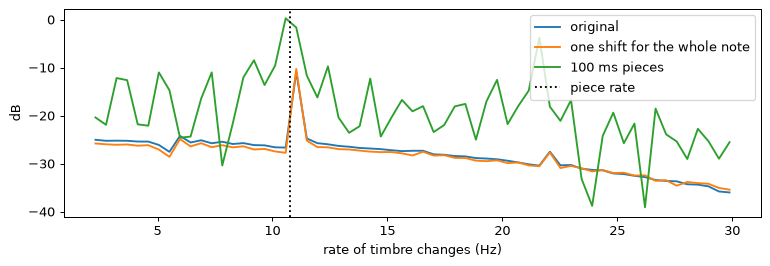

original (sags at the end)


pieces: listen for the flutter


one shift per note (the sag stays: it is human)


In [7]:
held = voice_like([62.4], note_s=2.5, vibrato_cents=25, drift_cents=-40)     # sags 40 cents
piece = int(0.093 * SR); a = int(0.05 * SR)
pieces = []
for k, p0 in enumerate(range(a, held.shape[1] - piece, piece)):              # 93 ms pieces, small varying shifts
    pieces.append(NoteShift(p0, p0 + piece, -0.4 + 0.15 * np.sin(k)))
chopped = apply_corrections(held, pieces)
one = apply_corrections(held, [NoteShift(a, held.shape[1] - int(0.05 * SR), -0.4)])

def timbre_rhythm(y, hop=220):
    S = np.abs(librosa.stft(np.asarray(y).reshape(-1)[int(0.2 * SR): -int(0.2 * SR)], n_fft=2048, hop_length=hop))
    S = S / (np.linalg.norm(S, axis=0, keepdims=True) + 1e-12)
    flux = 1 - (S[:, 1:] * S[:, :-1]).sum(0)
    f = np.fft.rfftfreq(len(flux), hop / SR); P = np.abs(np.fft.rfft(flux - flux.mean())) ** 2
    return f, 10 * np.log10(P + 1e-12)
fig, ax = plt.subplots(figsize=(10, 3))
for y, lab in [(held, "original"), (one, "one shift for the whole note"), (chopped, "100 ms pieces")]:
    f, P = timbre_rhythm(y); keep = (f > 2) & (f < 30); ax.plot(f[keep], P[keep], label=lab)
ax.axvline(SR / piece, color="k", ls=":", label="piece rate")
ax.set_xlabel("rate of timbre changes (Hz)"); ax.set_ylabel("dB"); ax.legend(); plt.show()
play(held, label="original (sags at the end)"); play(chopped, label="pieces: listen for the flutter"); play(one, label="one shift per note (the sag stays: it is human)")

The fix was to **give up drift correction**: one constant shift per note. A note that sags keeps its sag
(only its average pitch is fixed), which is in line with the product principle *preserve the performance*.
A natural sag sounds human; a flutter sounds broken.

## Summary

* Pitch shifting at constant duration = time-stretch (phase vocoder) + resample. The app uses Rubber Band.
* A voice is source (harmonics) × filter (formants). Shift the harmonics, keep the formants.
* Each note gets **one constant shift**, rendered separately with 100 ms of context, and is blended in with
  sin² crossfades that sum to 1. Everything else is the original, and timing never changes.
* Two lessons from real users: never use a per-sample shift curve (chirps), and never cut notes into
  differently shifted pieces (fan-like flutter).

Next: **notebook 6**, getting the voice alone out of a single recording.